# Capital IQ Transcripts on WRDS: Exploratory Analysis

Basic look at the S&P Capital IQ transcripts data on WRDS (`ciq_transcripts` / `ciq` schemas), as groundwork for the LLM-based earnings-surprise signal.

**Questions:**
1. What tables exist, how big are they, and how do they fit together?
2. How many earnings-call transcripts are there, and how does coverage change over time and by country?
3. How many versions does each call have (Preliminary vs Final), and how do we keep one per call?
4. How well do transcripts link to Compustat `gvkey`?
5. Timing: when are calls held, and how fast does the transcript appear?
6. Inside a call: how long are calls, how much is prepared remarks vs Q&A, and how many analysts ask questions?
7. What does a reconstructed transcript look like?

All heavy aggregation runs on the WRDS server. The component table has about 93M rows, so we never pull it in full.

In [1]:
import wrds
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)
pd.set_option('display.max_colwidth', 80)

# Restrained chart style: one hue, recessive grid/axes
BLUE, ORANGE = '#2a78d6', '#eb6834'
INK, INK2 = '#0b0b0b', '#52514e'
plt.rcParams.update({
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb',
    'axes.edgecolor': '#c3c2b7', 'axes.labelcolor': INK2, 'text.color': INK,
    'xtick.color': INK2, 'ytick.color': INK2,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#e8e7e3', 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'figure.figsize': (10, 4), 'figure.dpi': 110, 'lines.linewidth': 2,
})

db = wrds.Connection()  # uses pgpass credentials

Loading library list...
Done


## 1. Table inventory

In [2]:
libs = [l for l in db.list_libraries() if 'transcript' in l]
print('Transcript libraries:', libs)

sizes = db.raw_sql('''
    select c.relname as table_name, c.reltuples::bigint as approx_rows
    from pg_class c join pg_namespace n on n.oid = c.relnamespace
    where n.nspname = 'ciq_transcripts' and c.relkind in ('r','v','m','f')
    order by approx_rows desc
''')
sizes

Transcript libraries: ['ciq_transcripts', 'ciqsamp_transcripts']


,table_name,approx_rows
0,ciqtranscriptcomponent,93516792
1,wrds_transcript_person,93396968
2,wrds_transcript_detail,1824772
3,ciqtranscript,1790692
4,ciqtranscriptperson,575706
5,ciqtranscriptdelayreason,46769
6,ciqtranscriptdelayreasontype,19
7,ciqtranscriptcollectiontype,10
8,ciqtranscriptcomponenttype,8
9,ciqtranscriptspeakertype,6


**How the tables fit together**

| Table | Grain | Role |
|---|---|---|
| `ciqtranscript` | one row per transcript *version* | `transcriptid`, the `keydevid` (event), collection/presentation type, creation time, audio length |
| `wrds_transcript_detail` | same, plus event info | WRDS convenience view: adds `companyid`, `companyname`, event type, event date/time, headline |
| `ciqtranscriptcomponent` | one row per speaker turn | full text (`componenttext`), order, component type, `transcriptpersonid` |
| `wrds_transcript_person` | same, plus speaker info | adds speaker name/type, `word_count`, and a text preview (no full text) |
| `ciqtranscriptperson` | one row per speaker | name, company, speaker type, `proid` (CIQ professional ID) |
| `*type` tables | lookups | collection, component, presentation, speaker, delay reason |

Keys: **`keydevid`** = the event (e.g. AAPL Q3 2024 call). **`transcriptid`** = one version of that event's transcript. **`companyid`** = CIQ company, which links to Compustat through `ciq.wrds_gvkey`.

In [3]:
for t in ['ciqtranscriptcollectiontype', 'ciqtranscriptpresentationtype',
          'ciqtranscriptcomponenttype', 'ciqtranscriptspeakertype']:
    lk_ = db.raw_sql(f'select * from ciq_transcripts.{t}')
    display(lk_.set_index(lk_.columns[0]).T)

transcriptcollectiontypeid,1.0,2.0,6.0,7.0,8.0,9.0,10.0,11.0,13.0,24.0
transcriptcollectiontypename,Proofed Copy,Edited Copy,SA Edited Copy,Spellchecked Copy,Audited Copy,SA Spellchecked Copy,SA Proofed Copy,SA Audited Copy,EV Copy,AI Preliminary Copy


transcriptpresentationtypeid,4,5
transcriptpresentationtypename,Preliminary,Final


transcriptcomponenttypeid,1,2,3,4,5,6,7,8
transcriptcomponenttypename,Presentation Operator Message,Presenter Speech,Question,Answer,Presentation Section,Question And Answer Section,Question and Answer Operator Message,Unknown Question and Answer Message


speakertypeid,1,2,3,4,5,6
speakertypename,Operator,Executives,Analysts,Shareholders,Attendees,Unknown Speaker


## 2. Event types: which kinds of calls are covered?

In [4]:
evt = db.raw_sql('''
    select keydeveventtypename as event_type,
           count(*)                 as n_transcripts,
           count(distinct keydevid) as n_events,
           count(distinct companyid) as n_companies
    from ciq_transcripts.wrds_transcript_detail
    group by 1 order by n_transcripts desc
''')
evt['pct_of_events'] = evt.n_events / evt.n_events.sum()
evt.style.format({'n_transcripts': '{:,.0f}', 'n_events': '{:,.0f}', 'n_companies': '{:,.0f}', 'pct_of_events': '{:.1%}'})

,event_type,n_transcripts,n_events,n_companies,pct_of_events
0,Earnings Calls,"1,313,544","412,611","16,623",73.7%
1,Company Conference Presentations,"247,371","75,550","5,449",13.5%
2,Shareholder/Analyst Calls,"78,548","24,301","6,665",4.3%
3,Special Calls,"65,212","20,106","6,102",3.6%
4,M&A Calls,"49,031","7,240","9,700",1.3%
5,Analyst/Investor Day,"40,084","10,916","4,386",1.9%
6,Sales/Trading Statement Calls,"18,681","5,719",702,1.0%
7,Guidance/Update Calls,"4,846","1,424",887,0.3%
8,Interim Management Statement Calls,"3,165",914,183,0.2%
9,Operating Results Calls,"2,295",679,150,0.1%


Earnings calls (`keydeveventtypeid = 48`) are about 74% of events (412,611 events, 16.6k companies). **The rest of the notebook covers earnings calls only.**

Each earnings event has about 3.2 transcript versions on average (1.31M transcripts for 413k events), so next we look at what those versions are.

## 3. Multiple versions per event, and deduplication

In [5]:
ver = db.raw_sql('''
    select transcriptpresentationtypename as presentation,
           transcriptcollectiontypename   as collection,
           count(*) as n
    from ciq_transcripts.wrds_transcript_detail
    where keydeveventtypeid = 48
    group by 1, 2 order by n desc
''')
ver['pct'] = ver.n / ver.n.sum()
display(ver.style.format({'n': '{:,.0f}', 'pct': '{:.1%}'}))

nver = db.raw_sql('''
    select n_versions, count(*) as n_events from (
        select keydevid, count(*) as n_versions
        from ciq_transcripts.wrds_transcript_detail
        where keydeveventtypeid = 48 group by 1) s
    group by 1 order by 1
''')
nver['pct'] = nver.n_events / nver.n_events.sum()
nver.head(10).style.format({'n_events': '{:,.0f}', 'pct': '{:.1%}'})

,presentation,collection,n,pct
0,Preliminary,Spellchecked Copy,"367,401",28.0%
1,Final,Edited Copy,"362,697",27.6%
2,Final,Audited Copy,"238,344",18.1%
3,Final,Proofed Copy,"229,409",17.5%
4,Final,EV Copy,"53,716",4.1%
5,Final,SA Edited Copy,"32,774",2.5%
6,Final,SA Proofed Copy,"9,837",0.7%
7,Preliminary,SA Spellchecked Copy,"9,626",0.7%
8,Final,SA Audited Copy,"8,008",0.6%
9,Preliminary,AI Preliminary Copy,"1,732",0.1%


,n_versions,n_events,pct
0,1,"28,078",6.8%
1,2,"105,824",25.6%
2,3,"111,685",27.1%
3,4,"121,224",29.4%
4,5,"30,311",7.3%
5,6,"10,205",2.5%
6,7,"3,155",0.8%
7,8,"1,440",0.3%
8,9,296,0.1%
9,10,205,0.0%


**Dedup rule:** keep one transcript per `keydevid`. Prefer a **Final** version, then the most recently created, then the highest `transcriptid`. Postgres `DISTINCT ON` does this on the server.

We also pull country (from `ciq.ciqcompany`) and the Compustat `gvkey` link at the same time.

In [6]:
calls = db.raw_sql('''
    with dedup as (
        select distinct on (keydevid)
               keydevid, transcriptid, companyid, companyname,
               mostimportantdateutc as call_date, mostimportanttimeutc as call_time_utc,
               transcriptpresentationtypename as presentation,
               transcriptcollectiontypename as collection,
               transcriptcreationdate_utc as created_date,
               audiolengthsec
        from ciq_transcripts.wrds_transcript_detail
        where keydeveventtypeid = 48
        order by keydevid,
                 (transcriptpresentationtypeid = 5) desc,
                 transcriptcreationdate_utc desc, transcriptcreationtime_utc desc,
                 transcriptid desc
    )
    select d.*, g.country, g.isocountry2, g.region
    from dedup d
    left join ciq.ciqcompany c   on c.companyid = d.companyid
    left join ciq.ciqcountrygeo g on g.countryid = c.countryid
''', date_cols=['call_date', 'created_date'])

calls['year'] = calls.call_date.dt.year
print(f'{len(calls):,} unique earnings-call events, {calls.companyid.nunique():,} companies')
print(f'Final version available: {(calls.presentation == "Final").mean():.1%}')
print(f'Missing companyid: {calls.companyid.isna().mean():.2%}')
calls.head()

412,611 unique earnings-call events, 16,603 companies
Final version available: 100.0%
Missing companyid: 0.00%


,keydevid,transcriptid,companyid,companyname,call_date,call_time_utc,presentation,collection,created_date,audiolengthsec,country,isocountry2,region,year
0,1018019.0,708.0,353867.0,Abercrombie & Fitch Co.,2005-02-15,21:30:00,Final,SA Edited Copy,2008-06-20,<NA>,United States,US,United States and Canada,2005
1,1026789.0,4672.0,398006.0,Infosys Limited,2005-01-12,13:30:00,Final,SA Edited Copy,2008-06-20,<NA>,India,IN,Asia / Pacific,2005
2,1034137.0,359699.0,410350.0,Heineken N.V.,2004-09-08,14:00:00,Final,Audited Copy,2012-09-20,4634.0,Netherlands,NL,Europe,2004
3,1533032.0,3622293.0,24625.0,"Alloy, Inc.",2005-04-14,21:00:00,Final,Audited Copy,2025-12-17,<NA>,United States,US,United States and Canada,2005
4,1612017.0,3902.0,1342560.0,GameStop Corp.,2005-05-24,15:00:00,Final,SA Edited Copy,2008-06-20,<NA>,United States,US,United States and Canada,2005


## 4. Coverage over time

year,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
n_calls,1,68,1296,2960,10368,10760,13923,17999,18167,17902,18008,17982,17881,20313,22985,24023,26713,27864,29574,30015,29990,30685,23134
n_companies,1,63,440,1642,3574,3195,4464,5157,5175,5011,5019,5101,5218,6302,6832,7104,7996,8461,8835,8918,9060,9260,8976


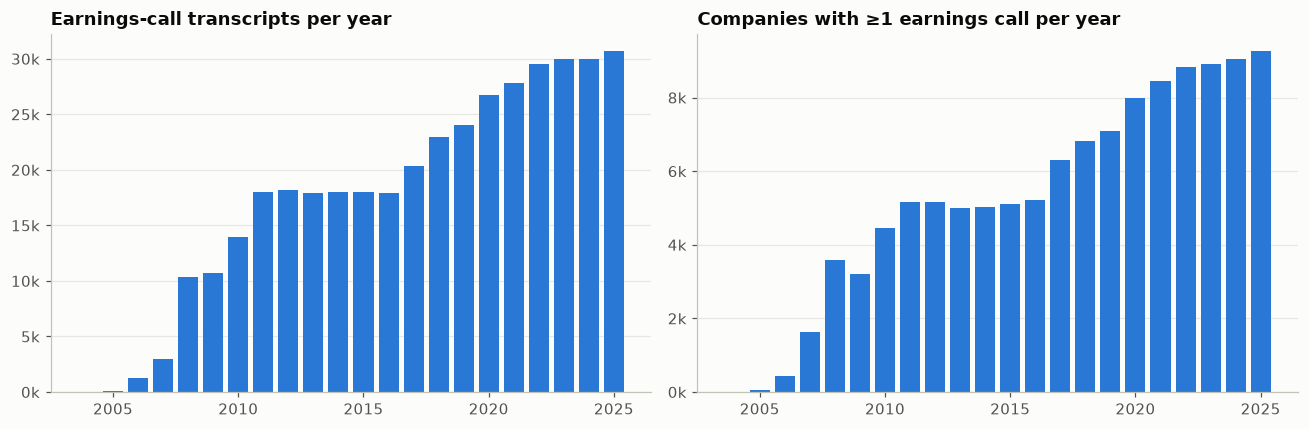

In [7]:
by_year = calls.groupby('year').agg(n_calls=('keydevid', 'size'), n_companies=('companyid', 'nunique'))
display(by_year.T)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col, title in [(axes[0], 'n_calls', 'Earnings-call transcripts per year'),
                       (axes[1], 'n_companies', 'Companies with ≥1 earnings call per year')]:
    s = by_year[col]
    s = s[s.index < pd.Timestamp.today().year]  # drop partial current year
    ax.bar(s.index, s.values, color=BLUE, width=0.8)
    ax.set_title(title)
    ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'{x/1000:.0f}k'))
    ax.grid(axis='x', visible=False)
plt.tight_layout(); plt.show()

Notes:
- Coverage is thin before 2008. From 2008 on there are about 10k–18k calls a year, rising to about 30k a year (about 9k companies) by 2023–2025. Much of the growth comes from international firms being added.
- Most company-years have 4 calls (quarterly reporters). Years with 1–3 calls are firms entering or leaving coverage, or semi-annual reporters outside the US.
- The current year is partial, so it is left out of the charts.

In [8]:
# Calls per company-year: about 4 means quarterly reporters
cy = calls.groupby(['companyid', 'year']).size()
print('Calls per company-year (2010+):')
cy[cy.index.get_level_values('year') >= 2010].value_counts().sort_index().head(8)

Calls per company-year (2010+):


1    10188
2    19218
3    14221
4    71742
5      807
6      388
7      101
8      199
Name: count, dtype: int64

### Seasonality: calls by month

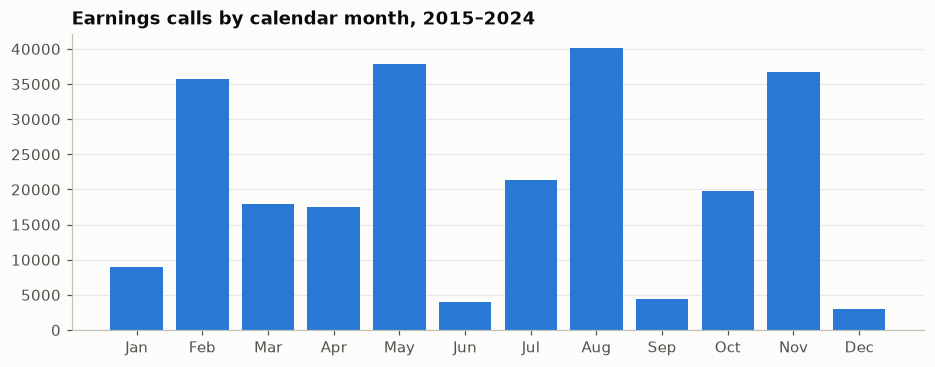

In [9]:
m = calls[calls.year.between(2015, 2024)].call_date.dt.month.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.bar(m.index, m.values, color=BLUE, width=0.8)
ax.set_xticks(range(1, 13), ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec'])
ax.set_title('Earnings calls by calendar month, 2015–2024')
ax.grid(axis='x', visible=False)
plt.show()

## 5. Geography

,n_calls,pct
country,,
United States,"64,939",45.0%
India,"12,099",8.4%
Canada,"9,797",6.8%
United Kingdom,"5,784",4.0%
Sweden,"4,916",3.4%
Australia,"4,612",3.2%
Germany,"3,562",2.5%
Brazil,"3,365",2.3%
Norway,"2,435",1.7%


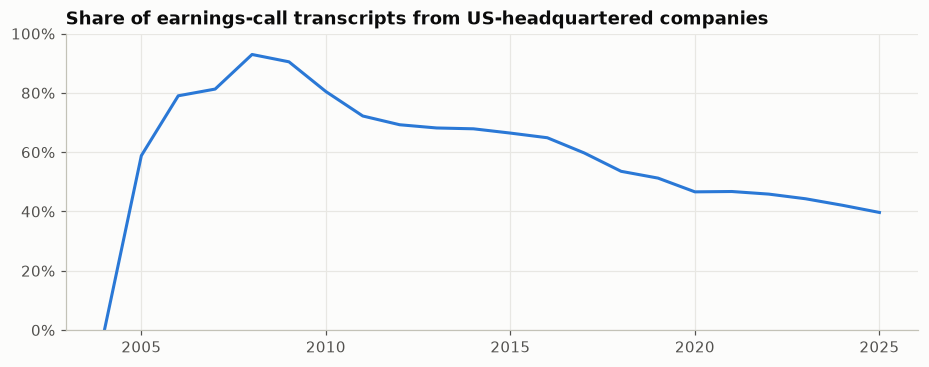

In [10]:
recent = calls[calls.year.between(2020, 2024)]
geo = recent.country.value_counts(dropna=False)
geo_pct = (geo / geo.sum()).head(15)
display(pd.DataFrame({'n_calls': geo.head(15), 'pct': geo_pct}).style.format({'n_calls': '{:,.0f}', 'pct': '{:.1%}'}))

us_share = calls.assign(us=calls.isocountry2.eq('US')).groupby('year').us.mean()
fig, ax = plt.subplots(figsize=(10, 3.5))
s = us_share[(us_share.index >= 2002) & (us_share.index < pd.Timestamp.today().year)]
ax.plot(s.index, s.values, color=BLUE)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_ylim(0, 1)
ax.set_title('Share of earnings-call transcripts from US-headquartered companies')
plt.show()

## 6. Link to Compustat (gvkey)

In [11]:
gv = db.raw_sql('select companyid, gvkey, startdate, enddate, primaryflag from ciq.wrds_gvkey',
                date_cols=['startdate', 'enddate'])
print(f'{len(gv):,} companyid-gvkey rows; companyids mapping to >1 gvkey: {(gv.groupby("companyid").gvkey.nunique() > 1).sum():,}')

# Date-aware link: missing start/end dates are treated as open-ended
lk = calls[['keydevid', 'companyid', 'call_date', 'year', 'isocountry2']].merge(gv, on='companyid', how='left')
ok = (lk.startdate.isna() | (lk.call_date >= lk.startdate)) & (lk.enddate.isna() | (lk.call_date <= lk.enddate))
lk = lk[ok | lk.gvkey.isna()].sort_values('primaryflag', ascending=False).drop_duplicates('keydevid')
calls = calls.merge(lk[['keydevid', 'gvkey']], on='keydevid', how='left')

link = calls.assign(linked=calls.gvkey.notna(), us=calls.isocountry2.eq('US'))
print(f'Overall share of calls linked to a gvkey: {link.linked.mean():.1%}')
print(f'US calls linked: {link[link.us].linked.mean():.1%} | Non-US: {link[~link.us].linked.mean():.1%}')
print(f'Unique gvkeys with ≥1 earnings call: {calls.gvkey.nunique():,}')
link.groupby('year').linked.mean().loc[2005:].to_frame('pct_linked').T.style.format('{:.0%}')

145,303 companyid-gvkey rows; companyids mapping to >1 gvkey: 524
Overall share of calls linked to a gvkey: 99.7%
US calls linked: 99.7% | Non-US: 99.7%
Unique gvkeys with ≥1 earnings call: 16,367


year,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
pct_linked,99%,100%,100%,100%,100%,100%,99%,100%,100%,100%,100%,100%,100%,100%,100%,100%,100%,100%,100%,100%,100%,100%


## 7. Timing: call time of day and transcript availability lag

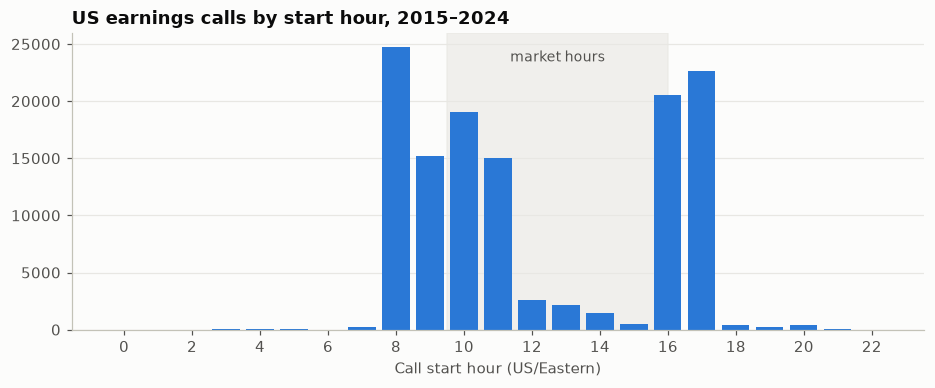

,share
session,
post-market (≥16:00),35.3%
intraday,32.5%
pre-market (<9:30),32.1%


In [12]:
# Event time is stored in UTC. Convert to US/Eastern for US firms to see pre/post-market timing.
us = calls[calls.isocountry2.eq('US') & calls.call_time_utc.notna() & calls.year.between(2015, 2024)].copy()
ts = pd.to_datetime(us.call_date.dt.strftime('%Y-%m-%d') + ' ' + us.call_time_utc.astype(str), utc=True)
us['hour_et'] = ts.dt.tz_convert('America/New_York').dt.hour

h = us.hour_et.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.bar(h.index, h.values, color=BLUE, width=0.8)
ax.axvspan(9.5, 16, color='#e8e7e3', alpha=0.6, zorder=0)
ax.text(12.75, h.max() * 0.95, 'market hours', ha='center', color=INK2, fontsize=9)
ax.set_xlabel('Call start hour (US/Eastern)'); ax.set_xticks(range(0, 24, 2))
ax.set_title('US earnings calls by start hour, 2015–2024')
ax.grid(axis='x', visible=False)
plt.show()

us['session'] = pd.cut(us.hour_et, [-1, 9, 15, 24], labels=['pre-market (<9:30)', 'intraday', 'post-market (≥16:00)'])
us.session.value_counts(normalize=True).to_frame('share').style.format('{:.1%}')

In [13]:
calls['lag_days'] = (calls.created_date - calls.call_date).dt.days
lag = calls[calls.year.between(2015, 2024)].lag_days
print('Days from call to (selected-version) transcript creation, 2015–2024:')
display(lag.describe(percentiles=[.1, .25, .5, .75, .9, .99]).to_frame().T)

# Fastest version of any kind, which matters for real-time signal construction
first = db.raw_sql('''
    select d.keydevid,
           min(d.transcriptcreationdate_utc - d.mostimportantdateutc) as first_lag_days
    from ciq_transcripts.wrds_transcript_detail d
    where d.keydeveventtypeid = 48 and d.mostimportantdateutc between '2015-01-01' and '2024-12-31'
    group by 1
''')
print('Days from call to FIRST available version (any type):')
first.first_lag_days.clip(-1, 30).value_counts(normalize=True).sort_index().head(8).to_frame('share').style.format('{:.1%}')

Days from call to (selected-version) transcript creation, 2015–2024:


,count,mean,std,min,10%,25%,50%,75%,90%,99%,max
lag_days,247340.0,43.571388,179.230824,0.0,0.0,0.0,2.0,18.0,65.0,1007.61,4053.0


Days from call to FIRST available version (any type):


,share
first_lag_days,
0,83.5%
1,10.3%
2,1.1%
3,0.7%
4,0.7%
5,0.4%
6,0.2%
7,0.2%


In practice: about 84% of events have *some* version created on the call date and about 94% within 1 day. The selected (Final) version has a median lag of 2 days and a long tail: the 90th percentile is 65 days, which includes backfilled history.

Note for signal construction: when backtesting, use the creation timestamp of the version you use, not just the call date. A Final version can show up days after the call, while a Preliminary or AI-generated copy is often ready the same day.

## 8. Inside the transcripts: length, structure, speakers

Component-level stats come from `wrds_transcript_person` (it has `word_count`), aggregated on the server for the **deduped 2023 earnings calls**.

In [14]:
SAMPLE_YEAR = 2023
ids = calls.loc[calls.year == SAMPLE_YEAR, 'transcriptid'].astype(int)
# Push the transcript id list to the server through a VALUES list
id_values = ','.join(f'({i})' for i in ids)

comp = db.raw_sql(f'''
    with ids(transcriptid) as (values {id_values})
    select p.transcriptid,
           count(*)                                                        as n_components,
           sum(p.word_count)                                               as words_total,
           sum(case when p.transcriptcomponenttypeid = 2 then p.word_count else 0 end) as words_presentation,
           sum(case when p.transcriptcomponenttypeid in (3,4) then p.word_count else 0 end) as words_qa,
           sum(case when p.transcriptcomponenttypeid = 3 then 1 else 0 end) as n_questions,
           count(distinct case when p.speakertypeid = 3 then p.transcriptpersonid end) as n_analysts,
           count(distinct case when p.speakertypeid = 2 then p.transcriptpersonid end) as n_executives
    from ciq_transcripts.wrds_transcript_person p
    join ids using (transcriptid)
    group by 1
''')
comp = comp.merge(calls[['transcriptid', 'audiolengthsec', 'isocountry2', 'companyname']].assign(transcriptid=lambda d: d.transcriptid.astype(int)),
                  on='transcriptid', how='left')
comp['qa_share'] = comp.words_qa / comp.words_total
comp['audio_min'] = comp.audiolengthsec / 60
print(f'{len(comp):,} transcripts from {SAMPLE_YEAR}')
comp[['n_components', 'words_total', 'words_presentation', 'words_qa', 'qa_share',
      'n_questions', 'n_analysts', 'n_executives', 'audio_min']].describe(percentiles=[.1, .5, .9]).T.round(2)

30,015 transcripts from 2023


,count,mean,std,min,10%,50%,90%,max
n_components,30015.0,47.31,32.34,1.0,15.0,41.0,84.0,327.0
words_total,30015.0,6433.43,2618.73,151.0,3175.0,6298.0,9630.2,33067.0
words_presentation,30015.0,2831.99,1420.01,0.0,1260.0,2649.0,4563.0,18812.0
words_qa,30015.0,3445.42,2141.21,0.0,818.0,3235.0,6285.6,17834.0
qa_share,30015.0,0.5,0.21,0.0,0.22,0.52,0.75,1.0
n_questions,30015.0,14.23,13.49,0.0,0.0,12.0,28.0,140.0
n_analysts,30015.0,4.83,3.76,0.0,0.0,4.0,10.0,25.0
n_executives,30015.0,3.06,1.2,0.0,2.0,3.0,5.0,13.0
audio_min,30005.0,47.19,18.05,1.02,24.41,46.8,67.85,295.85


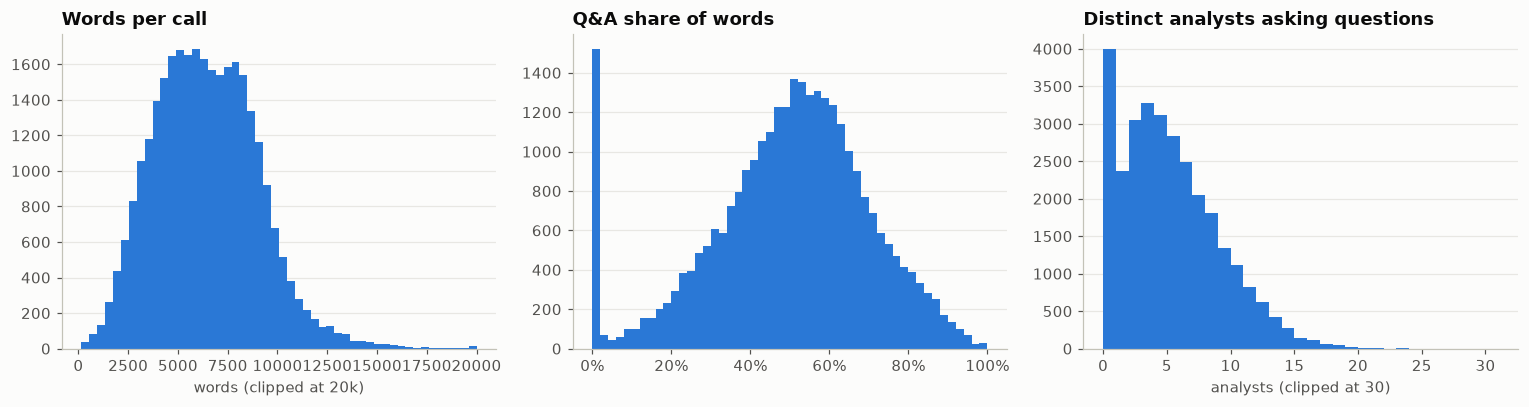

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
axes[0].hist(comp.words_total.clip(upper=20000), bins=50, color=BLUE)
axes[0].set_title('Words per call'); axes[0].set_xlabel('words (clipped at 20k)')
axes[1].hist(comp.qa_share.dropna(), bins=50, color=BLUE)
axes[1].set_title('Q&A share of words'); axes[1].xaxis.set_major_formatter(mtick.PercentFormatter(1))
axes[2].hist(comp.n_analysts.clip(upper=30), bins=range(0, 32), color=BLUE)
axes[2].set_title('Distinct analysts asking questions'); axes[2].set_xlabel('analysts (clipped at 30)')
for ax in axes: ax.grid(axis='x', visible=False)
plt.tight_layout(); plt.show()

In [16]:
# US vs. non-US structure
comp.assign(us=comp.isocountry2.eq('US')).groupby('us')[
    ['words_total', 'qa_share', 'n_questions', 'n_analysts', 'audio_min']].median().round(2)

,words_total,qa_share,n_questions,n_analysts,audio_min
us,,,,,
False,6355.5,0.51,10.0,4.0,49.17
True,6245.0,0.52,13.0,5.0,44.4


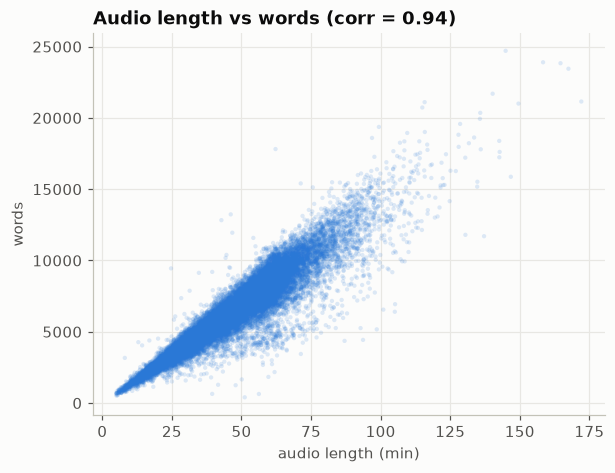

Implied speaking rate: median 138 words/min


In [17]:
# Does audio length track transcript length? (sanity check on audiolengthsec)
c = comp.dropna(subset=['audio_min'])
c = c[(c.audio_min > 5) & (c.audio_min < 180)]
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.scatter(c.audio_min, c.words_total, s=8, alpha=0.15, color=BLUE, edgecolors='none')
ax.set_xlabel('audio length (min)'); ax.set_ylabel('words')
ax.set_title(f'Audio length vs words (corr = {c.audio_min.corr(c.words_total):.2f})')
plt.show()
print(f'Implied speaking rate: median {(c.words_total / c.audio_min).median():.0f} words/min')

In [18]:
# Speaker-type mix by words, all 2023 calls
spk = db.raw_sql(f'''
    with ids(transcriptid) as (values {id_values})
    select coalesce(p.speakertypename, 'Missing') as speaker_type,
           p.transcriptcomponenttypename as component_type,
           count(*) as n_components, sum(p.word_count) as words
    from ciq_transcripts.wrds_transcript_person p join ids using (transcriptid)
    group by 1, 2 order by words desc
''')
spk['pct_words'] = spk.words / spk.words.sum()
spk.style.format({'n_components': '{:,.0f}', 'words': '{:,.0f}', 'pct_words': '{:.1%}'})

,speaker_type,component_type,n_components,words,pct_words
0,Executives,Presenter Speech,"107,305","84,170,039",43.6%
1,Executives,Answer,"642,368","77,449,752",40.1%
2,Analysts,Question,"427,063","25,253,664",13.1%
3,Operator,Question and Answer Operator Message,"197,304","2,996,700",1.6%
4,Operator,Presentation Operator Message,"25,614","1,686,000",0.9%
5,Attendees,Presenter Speech,"2,996","695,641",0.4%
6,Attendees,Answer,"14,657","655,666",0.3%
7,Analysts,Presenter Speech,"1,379","136,587",0.1%
8,Shareholders,Answer,"1,202","55,287",0.0%


## 9. Reconstruct one full transcript

Full text is in `ciqtranscriptcomponent.componenttext`. We join speaker info from `ciqtranscriptperson` and sort by `componentorder`. Example: Apple's most recent earnings call in the data.

In [19]:
aapl = calls[calls.companyname.str.fullmatch('Apple Inc.', na=False)].sort_values('call_date')
print(aapl[['call_date', 'transcriptid', 'presentation', 'collection']].tail(5).to_string(index=False))
tid = int(aapl.transcriptid.iloc[-1])

tx = db.raw_sql(f'''
    select c.componentorder, ct.transcriptcomponenttypename as component_type,
           p.transcriptpersonname as speaker, st.speakertypename as speaker_type,
           p.companyname as speaker_company, c.componenttext
    from ciq_transcripts.ciqtranscriptcomponent c
    left join ciq_transcripts.ciqtranscriptcomponenttype ct using (transcriptcomponenttypeid)
    left join ciq_transcripts.ciqtranscriptperson p using (transcriptpersonid)
    left join ciq_transcripts.ciqtranscriptspeakertype st on st.speakertypeid = p.speakertypeid
    where c.transcriptid = {tid}
    order by c.componentorder
''')
print(f'\ntranscriptid {tid}: {len(tx)} components, {tx.componenttext.str.split().str.len().sum():,} words')
tx.assign(preview=tx.componenttext.str[:120]).drop(columns='componenttext').head(15)

 call_date  transcriptid presentation   collection
2025-07-31     3511233.0        Final  Edited Copy
2025-10-30     3580091.0        Final Proofed Copy
2026-01-29     3643183.0        Final Proofed Copy
2026-04-30     3722606.0        Final Proofed Copy
2026-07-30     3792320.0        Final Proofed Copy

transcriptid 3792320: 49 components, 8,141 words


,componentorder,component_type,speaker,speaker_type,speaker_company,preview
0,0,Presenter Speech,Suhasini Chandramouli,Executives,<NA>,"Good afternoon, and welcome to the Apple Q3 Fiscal Year 2026 Earnings Confer..."
1,1,Presenter Speech,Timothy Cook,Executives,<NA>,"Thank you, Suhasini. Good afternoon, everyone, and thanks for joining the ca..."
2,2,Presenter Speech,Kevan Parekh,Executives,<NA>,"Thanks, Tim, and good afternoon, everyone. Here's a quick rundown of our key..."
3,3,Presenter Speech,Timothy Cook,Executives,<NA>,"Thanks, Kevan. Before we get into questions, I just wanted to take a moment ..."
4,4,Answer,Suhasini Chandramouli,Executives,<NA>,"Thank you, Tim. [Operator Instructions]. Operator, may we have the first que..."
5,5,Question and Answer Operator Message,Operator,Operator,<NA>,"Certainly, we will go ahead and take our first question from Amit Daryanani ..."
6,6,Question,Amit Daryanani,Analysts,<NA>,"Tim, best of luck. It's been a pleasure working with you over the years. May..."
7,7,Answer,Kevan Parekh,Executives,<NA>,"Yes, Amit, this is Kevan. Why don't I start with just kind of describing the..."
8,8,Answer,Timothy Cook,Executives,<NA>,"Yes, Amit, it's Tim. First of all, thank you for your comments. During the J..."
9,9,Question,Amit Daryanani,Analysts,<NA>,"Got it. It's really helpful. And then Tim, I just have a memory question for..."


In [20]:
# Readable rendering of the first few turns of the Q&A
qa = tx[tx.component_type.isin(['Question', 'Answer'])].head(6)
for _, r in qa.iterrows():
    print(f'[{r.component_type}] {r.speaker} ({r.speaker_type}, {r.speaker_company})')
    print(r.componenttext[:600] + ('...' if len(r.componenttext) > 600 else ''), '\n')

[Answer] Suhasini Chandramouli (Executives, <NA>)
Thank you, Tim. [Operator Instructions]. Operator, may we have the first question, please. 

[Question] Amit Daryanani (Analysts, <NA>)
Tim, best of luck. It's been a pleasure working with you over the years. Maybe to start with, if I think about the 9% to 11% sort of growth that's guided for September, it's about 500 basis points or so deceleration versus what we've seen in really in June quarter even through this year, I would say. Can you just talk about how much of this decel is really supply constrained versus other factors like FX? And if you could just flesh out what these supply constraints are that broadening beyond these advanced SoCs you talked about last quarter as well? 

[Answer] Kevan Parekh (Executives, <NA>)
Yes, Amit, this is Kevan. Why don't I start with just kind of describing the sequential change, and then I'll let Tim jump into kind of a bit more color on the supply constraints. So I think as I mentioned in my pre

## 10. Takeaways for the earnings-surprise project

- **Scope:** filter to `keydeveventtypeid = 48` (Earnings Calls). That leaves about 413k unique events from 16.6k companies. Coverage is usable from 2008 and reaches about 30k calls a year recently. US companies are about 45% of calls in 2020–2024.
- **Dedup:** about 3.2 versions per event (Preliminary Spellchecked, then Final Edited/Proofed/Audited, etc.). Keep one per `keydevid`. For a point-in-time backtest, choose the version by **creation date relative to the trading decision**. A Preliminary copy is usually ready the same day; the Final copy has a median lag of 2 days.
- **Linking:** `companyid → gvkey` via `ciq.wrds_gvkey` covers about 99.7% of calls (16.4k gvkeys). Next steps: `gvkey → permno` (CCM) for returns, and `gvkey → IBES` for analyst consensus / numeric surprise.
- **Structure:** the prepared remarks vs Q&A split is clean (component type 2 vs 3/4), and speaker type separates executives from analysts. In 2023, executives' prepared remarks are about 44% of words, executives' answers about 40%, and analyst questions about 13%. The median call has about 4 distinct analysts and about 12 questions. Section-level features (e.g. the tone of the prepared remarks vs the tone of answers) are straightforward to build.
- **Size:** the median call is about 6.3k words (90th percentile about 9.6k) and about 47 minutes of audio, which fits comfortably in an LLM context window. All earnings calls together come to roughly 2.5B words, so plan batching and cost before scoring the full history.
- **Timing:** call start times for US firms split about evenly across pre-market, intraday and post-close. Call time is **not** the earnings release time (many firms release before the open and hold the call at 10–11am ET). For event windows, take the release timestamp from IBES/Compustat `rdq` or the CIQ key-dev "Announcements of Earnings" event, not from the call time.


In [21]:
db.close()